In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split

In [2]:
postings = pd.read_csv("C:\\Users\\Dell\\Downloads\\NTI_Project\\postings.csv")

In [3]:
print("Shape:", postings.shape)

display(postings.head())

Shape: (123849, 31)


,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.0,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,...,Requirements: \n\nWe are seeking a College or ...,1.713398e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,38480.0,8540.0,34021.0
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.0,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,...,NaN,1.712858e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,83200.0,80521.0,8069.0
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


In [4]:
postings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123849 entries, 0 to 123848
Data columns (total 31 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   job_id                      123849 non-null  int64  
 1   company_name                122130 non-null  object 
 2   title                       123849 non-null  object 
 3   description                 123842 non-null  object 
 4   max_salary                  29793 non-null   float64
 5   pay_period                  36073 non-null   object 
 6   location                    123849 non-null  object 
 7   company_id                  122132 non-null  float64
 8   views                       122160 non-null  float64
 9   med_salary                  6280 non-null    float64
 10  min_salary                  29793 non-null   float64
 11  formatted_work_type         123849 non-null  object 
 12  applies                     23320 non-null   float64
 13  original_liste

In [5]:
profile = pd.DataFrame({
    "dtype": postings.dtypes,
    "missing": postings.isna().sum(),
    "missing_%": (postings.isna().mean() * 100).round(2),
    "unique": postings.nunique()
})

profile.sort_values("missing_%", ascending=False)

,dtype,missing,missing_%,unique
closed_time,float64,122776,99.13,698
skills_desc,object,121410,98.03,2212
med_salary,float64,117569,94.93,1417
remote_allowed,float64,108603,87.69,1
applies,float64,100529,81.17,274
max_salary,float64,94056,75.94,5321
min_salary,float64,94056,75.94,4612
currency,object,87776,70.87,6
compensation_type,object,87776,70.87,1
normalized_salary,float64,87776,70.87,7259


In [6]:
print("Duplicate job IDs:", postings["job_id"].duplicated().sum())

Duplicate job IDs: 0


In [7]:
categorical_cols = [
    "formatted_work_type",
    "formatted_experience_level",
    "application_type",
    "pay_period",
    "currency",
    "compensation_type"
]

for col in categorical_cols:
    print(f"\n{'='*50}")
    print(col)
    print(postings[col].value_counts(dropna=False))


formatted_work_type
formatted_work_type
Full-time     98814
Contract      12117
Part-time      9696
Temporary      1190
Internship      983
Volunteer       562
Other           487
Name: count, dtype: int64

formatted_experience_level
formatted_experience_level
Mid-Senior level    41489
Entry level         36708
NaN                 29409
Associate            9826
Director             3746
Internship           1449
Executive            1222
Name: count, dtype: int64

application_type
application_type
OffsiteApply          84607
ComplexOnsiteApply    31049
SimpleOnsiteApply      8192
UnknownApply              1
Name: count, dtype: int64

pay_period
pay_period
NaN         87776
YEARLY      20628
HOURLY      14741
MONTHLY       518
WEEKLY        177
BIWEEKLY        9
Name: count, dtype: int64

currency
currency
NaN    87776
USD    36058
EUR        6
CAD        3
BBD        2
AUD        2
GBP        2
Name: count, dtype: int64

compensation_type
compensation_type
NaN            87776
BASE_S

In [8]:
numeric_cols = [
    "views",
    "applies",
    "min_salary",
    "med_salary",
    "max_salary",
    "normalized_salary"
]

postings[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
views,122160.0,14.618247,8.590360e+01,1.0,3.00,4.0,8.0,9975.0
applies,23320.0,10.591981,2.904739e+01,1.0,1.00,3.0,8.0,967.0
min_salary,29793.0,64910.847434,4.959738e+05,1.0,37.00,60000.0,100000.0,85000000.0
med_salary,6280.0,22015.619876,5.225587e+04,0.0,18.94,25.5,2510.5,750000.0
max_salary,29793.0,91939.423461,7.011101e+05,1.0,48.28,80000.0,140000.0,120000000.0
normalized_salary,36073.0,205327.036850,5.097627e+06,0.0,52000.00,81500.0,125000.0,535600000.0


In [9]:
for col in numeric_cols:
    print(f"{col}: {(postings[col] < 0).sum()} negative values")

views: 0 negative values
applies: 0 negative values
min_salary: 0 negative values
med_salary: 0 negative values
max_salary: 0 negative values
normalized_salary: 0 negative values


In [10]:
for col in numeric_cols:
    print(f"{col}: {(postings[col] == 0).sum()} zero values")

views: 0 zero values
applies: 0 zero values
min_salary: 0 zero values
med_salary: 14 zero values
max_salary: 0 zero values
normalized_salary: 14 zero values


In [11]:
zero_salary = postings[
    (postings["med_salary"] == 0) |
    (postings["normalized_salary"] == 0)
]

zero_salary[
    [
        "job_id",
        "title",
        "min_salary",
        "med_salary",
        "max_salary",
        "pay_period",
        "currency",
        "normalized_salary"
    ]
]

,job_id,title,min_salary,med_salary,max_salary,pay_period,currency,normalized_salary
6395,3885114173,Independent Sales Representative,NaN,0.0,NaN,YEARLY,USD,0.0
8305,3885869218,Full-Stack Engineer Intern (Unpaid),NaN,0.0,NaN,YEARLY,USD,0.0
17594,3888041858,Sales Consultant (B2B),NaN,0.0,NaN,YEARLY,USD,0.0
25681,3891076695,Marketing Specialist,NaN,0.0,NaN,YEARLY,USD,0.0
39731,3898168102,Manager of Medical Systems Development (24-89),NaN,0.0,NaN,YEARLY,USD,0.0
46750,3900978299,UX/UI Designer,NaN,0.0,NaN,YEARLY,USD,0.0
60721,3901982077,Volunteer Scrum Master – Driving Nature Connec...,NaN,0.0,NaN,YEARLY,USD,0.0
62013,3902301244,Public Health Empowerment Pro Bono Coach,NaN,0.0,NaN,YEARLY,USD,0.0
62061,3902304280,Environmental Stewardship Pro Bono Coach,NaN,0.0,NaN,YEARLY,USD,0.0
62083,3902306286,Ikigai-Inspired Coach – CrowdDoing Pro Bono Co...,NaN,0.0,NaN,YEARLY,USD,0.0


In [12]:
print(
    "min > max:",
    (postings["min_salary"] > postings["max_salary"]).sum()
)

print(
    "med < min:",
    (postings["med_salary"] < postings["min_salary"]).sum()
)

print(
    "med > max:",
    (postings["med_salary"] > postings["max_salary"]).sum()
)

min > max: 0
med < min: 0
med > max: 0


In [13]:
df = postings.copy()

In [14]:
date_cols = [
    "original_listed_time",
    "listed_time",
    "expiry",
    "closed_time"
]

for col in date_cols:
    df[col] = pd.to_datetime(
        df[col],
        unit="ms",
        errors="coerce"
    )

In [15]:
df["formatted_experience_level"] = (
    df["formatted_experience_level"]
    .fillna("Not Specified")
)

In [16]:
df["company_name"] = (
    df["company_name"]
    .fillna("Unknown")
)

In [17]:
df["description"] = (
    df["description"]
    .fillna("")
    .astype(str)
)

In [18]:
df["is_remote"] = df["remote_allowed"].fillna(0).astype(int)

df["city"] = df["location"].apply(lambda x: str(x).split(",")[0].strip() if "," in str(x) else str(x).strip())
df["state_or_country"] = df["location"].apply(lambda x: str(x).split(",")[1].strip() if "," in str(x) else np.nan)

columns_to_drop = [
    "work_type",
    "closed_time",
    "skills_desc",
    "remote_allowed",
    "application_url"
]
df = df.drop(columns=columns_to_drop)

In [19]:
df["posting_year"] = df["listed_time"].dt.year
df["posting_month"] = df["listed_time"].dt.month
df["posting_month_name"] = df["listed_time"].dt.month_name()
df["posting_day"] = df["listed_time"].dt.day_name()

In [20]:
df["description_length"] = df["description"].str.len()

df["description_word_count"] = (
    df["description"]
    .str.split()
    .str.len()
)

In [21]:
df["application_rate"] = np.where(
    df["views"] > 0,
    df["applies"] / df["views"],
    np.nan
)

In [22]:
salary_df = df[
    df["normalized_salary"].notna()
].copy()

In [23]:
salary_usd = salary_df[
    (salary_df["currency"] == "USD") &
    (salary_df["normalized_salary"] >= 10000) &
    (salary_df["normalized_salary"] <= 500000)
].copy()

In [24]:
print("All jobs:", len(df))
print("Jobs with salary:", len(salary_df))
print("USD salary jobs:", len(salary_usd))

All jobs: 123849
Jobs with salary: 36073
USD salary jobs: 35546


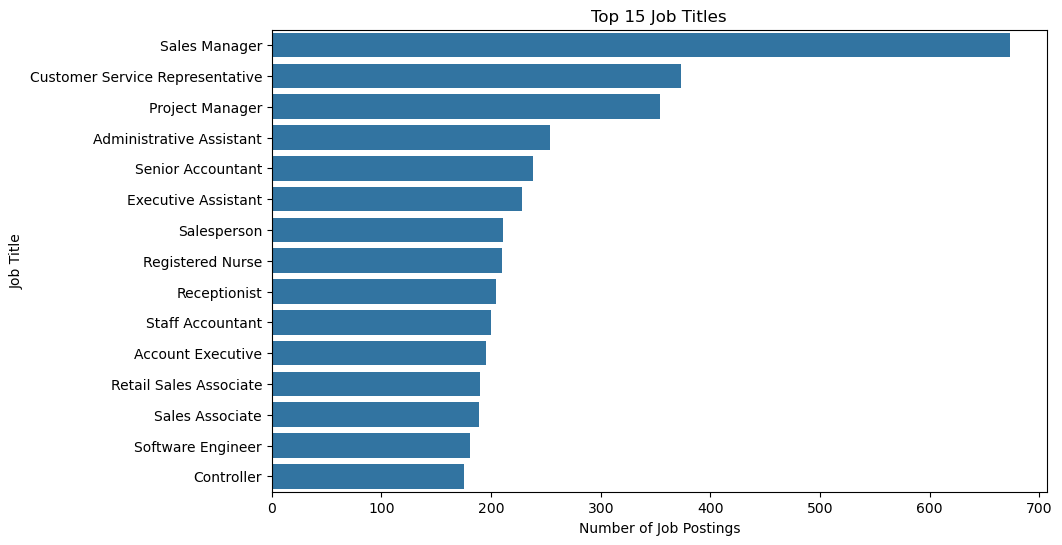

In [25]:
top_titles = (
    df["title"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_titles.values,
    y=top_titles.index
)

plt.title("Top 15 Job Titles")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Title")

plt.show()

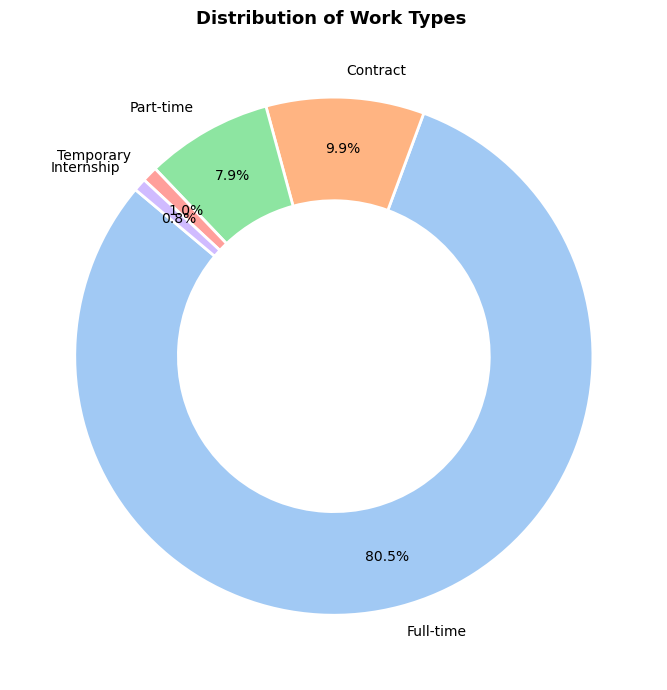

In [26]:
work_types = df["formatted_work_type"].value_counts().head(5)

plt.figure(figsize=(7, 7))
colors = sns.color_palette("pastel")

plt.pie(
    work_types.values,
    labels=work_types.index,
    autopct='%1.1f%%',
    pctdistance=0.80,
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)

plt.title("Distribution of Work Types ", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

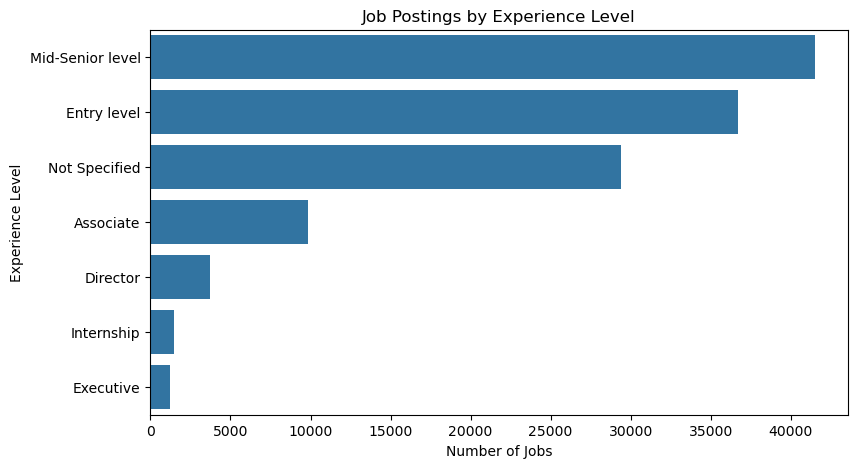

In [27]:
plt.figure(figsize=(9, 5))

order = df["formatted_experience_level"].value_counts().index

sns.countplot(
    data=df,
    y="formatted_experience_level",
    order=order
)

plt.title("Job Postings by Experience Level")
plt.xlabel("Number of Jobs")
plt.ylabel("Experience Level")

plt.show()

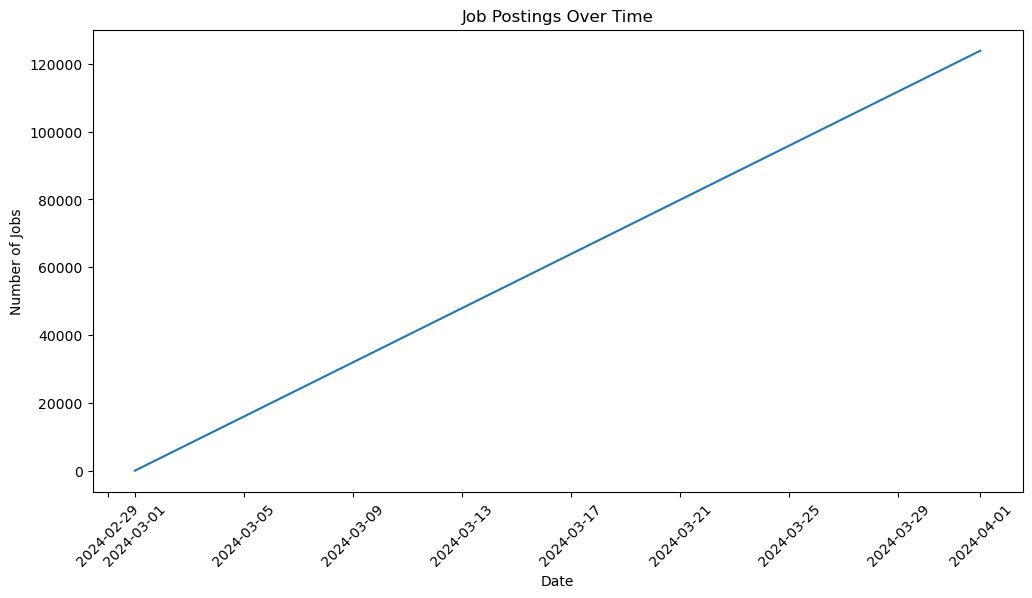

In [28]:
jobs_by_month = (
    df.groupby(df["listed_time"].dt.to_period("M"))
      .size()
)

jobs_by_month.index = jobs_by_month.index.to_timestamp()

plt.figure(figsize=(12, 6))

plt.plot(
    jobs_by_month.index,
    jobs_by_month.values
)

plt.title("Job Postings Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Jobs")

plt.xticks(rotation=45)
plt.show()

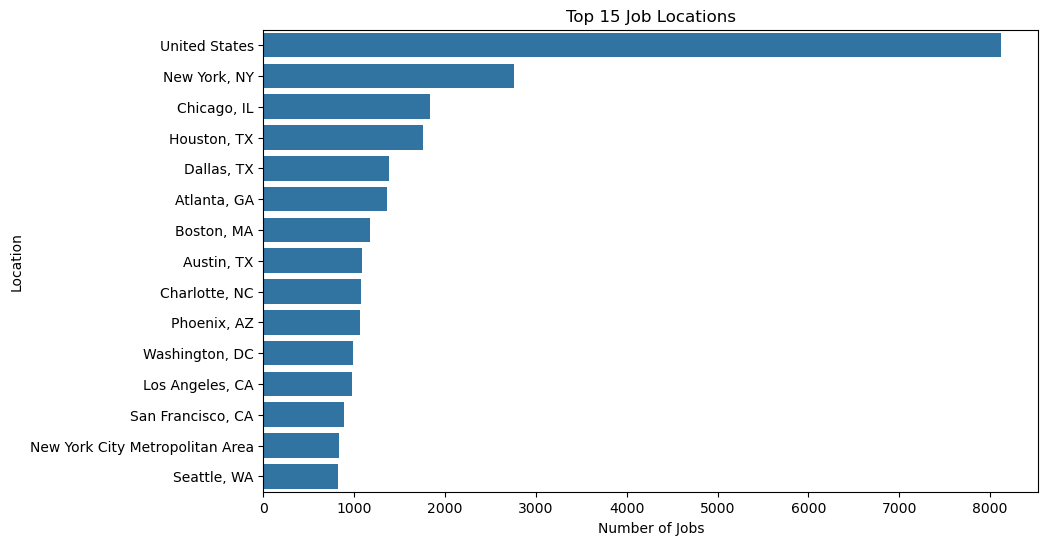

In [29]:
top_locations = (
    df["location"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title("Top 15 Job Locations")
plt.xlabel("Number of Jobs")
plt.ylabel("Location")

plt.show()

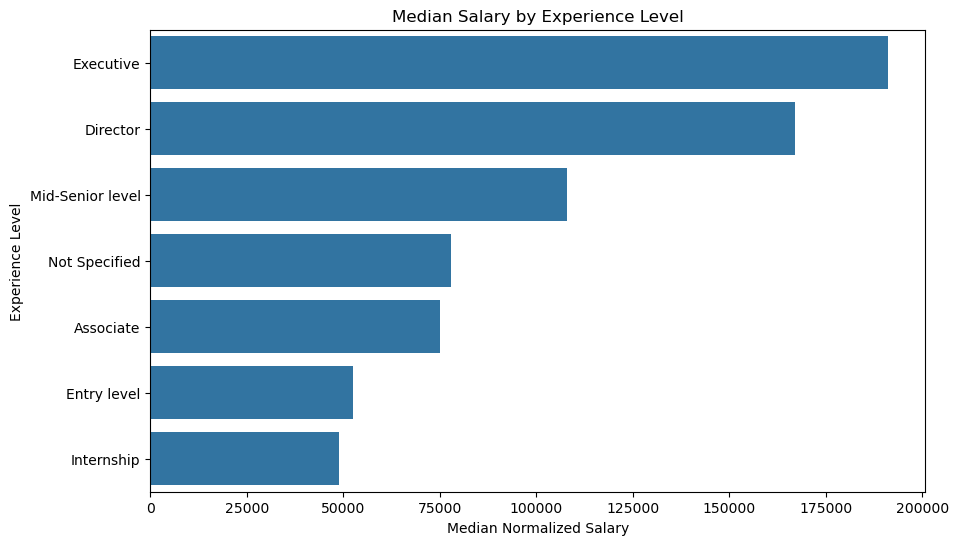

In [30]:
experience_salary = (
    salary_usd
    .groupby("formatted_experience_level")["normalized_salary"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=experience_salary.values,
    y=experience_salary.index
)

plt.title("Median Salary by Experience Level")
plt.xlabel("Median Normalized Salary")
plt.ylabel("Experience Level")

plt.show()

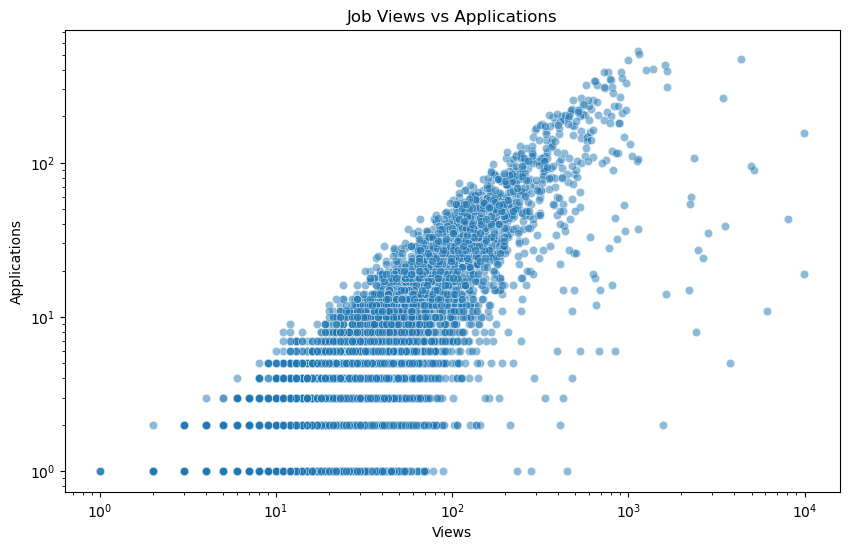

In [31]:
engagement_df = df[
    (df["views"] > 0) &
    (df["applies"] > 0)
].copy()
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=engagement_df.sample(
        min(10000, len(engagement_df)),
        random_state=42
    ),
    x="views",
    y="applies",
    alpha=0.5
)

plt.xscale("log")
plt.yscale("log")

plt.title("Job Views vs Applications")
plt.xlabel("Views")
plt.ylabel("Applications")

plt.show()

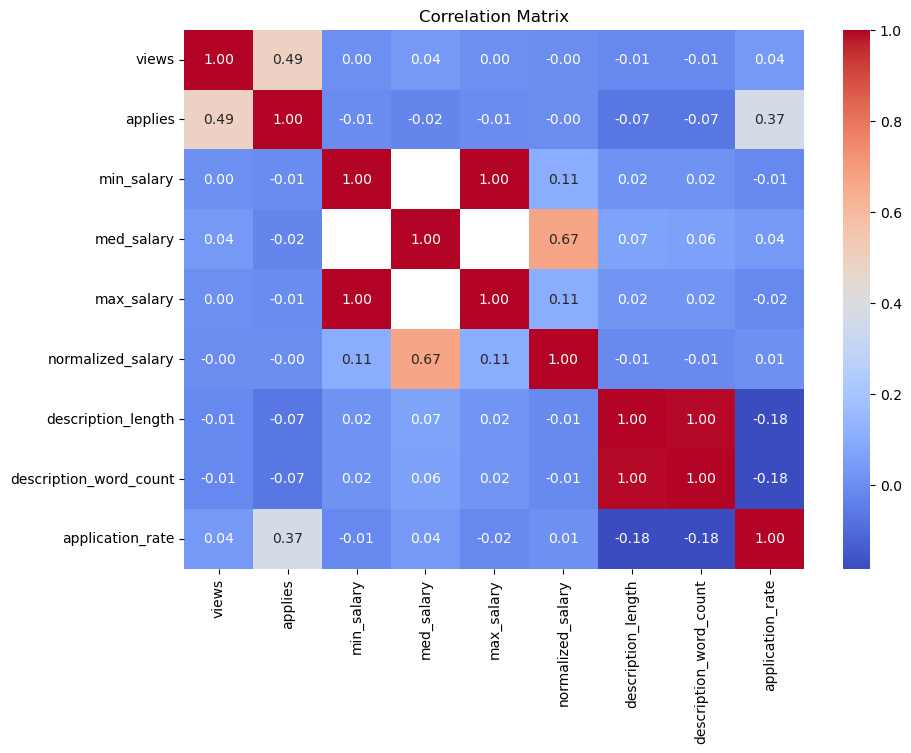

In [32]:
corr_cols = [
    "views",
    "applies",
    "min_salary",
    "med_salary",
    "max_salary",
    "normalized_salary",
    "description_length",
    "description_word_count",
    "application_rate"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

In [33]:
df.to_csv(
    "postings_clean22.csv",
    index=False
)

In [34]:
salary_usd.to_csv(
    "salary_model_data.csv",
    index=False
)

In [36]:
job_skills = pd.read_csv("C:\\Users\\Dell\\Downloads\\NTI_Project\\job_skills.csv")
skills = pd.read_csv("C:\\Users\\Dell\\Downloads\\NTI_Project\\skills.csv")

print(job_skills.shape)
print(skills.shape)

print(job_skills.columns)
print(skills.columns)

(213768, 2)
(35, 2)
Index(['job_id', 'skill_abr'], dtype='object')
Index(['skill_abr', 'skill_name'], dtype='object')


In [37]:
job_skills = job_skills.merge(
    skills,
    on="skill_abr",
    how="left"
)

In [38]:
job_skills.head()

,job_id,skill_abr,skill_name
0,3884428798,MRKT,Marketing
1,3884428798,PR,Public Relations
2,3884428798,WRT,Writing/Editing
3,3887473071,SALE,Sales
4,3887465684,FIN,Finance


In [40]:
job_skills_grouped = (
    job_skills
    .groupby("job_id")["skill_name"]
    .apply(lambda x: "  ".join(x.dropna().astype(str)))
    .reset_index()
)

job_skills_grouped.head()

,job_id,skill_name
0,921716,Marketing Sales
1,1218575,Health Care Provider
2,1829192,Health Care Provider
3,2264355,Design Art/Creative Information Technology
4,10998357,Management Manufacturing


In [41]:
ml_df = salary_usd.merge(
    job_skills_grouped,
    on="job_id",
    how="inner"
)

In [43]:
print(ml_df.shape)
ml_df[[
    "job_id",
    "formatted_experience_level",
    "formatted_work_type",
    "skill_name",
    "normalized_salary"
]].tail()

(35017, 37)


,job_id,formatted_experience_level,formatted_work_type,skill_name,normalized_salary
35012,3906265414,Mid-Senior level,Contract,Legal Finance Writing/Editing,83200.0
35013,3906266165,Associate,Part-time,Administrative,57500.0
35014,3906266272,Mid-Senior level,Contract,Engineering,83200.0
35015,3906267117,Mid-Senior level,Full-time,Legal Business Development,157500.0
35016,3906267224,Mid-Senior level,Full-time,Marketing,72500.0


In [44]:
ml_df["skill_name"].isna().sum()

0

In [45]:
X = ml_df[
    [
        "formatted_experience_level",
        "formatted_work_type",
        "skill_name"
    ]
]

In [46]:
y = ml_df["normalized_salary"]

In [47]:
print(X.shape)
print(y.shape)

display(X.head())
display(y.head())

(35017, 3)
(35017,)


,formatted_experience_level,formatted_work_type,skill_name
0,Not Specified,Full-time,Marketing Sales
1,Not Specified,Full-time,Health Care Provider
2,Not Specified,Full-time,Management Manufacturing
3,Not Specified,Full-time,Other
4,Not Specified,Full-time,Information Technology


0     38480.0
1     83200.0
2     55000.0
3    157500.0
4     70000.0
Name: normalized_salary, dtype: float64

In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (28013, 3)
X_test : (7004, 3)
y_train: (28013,)
y_test : (7004,)


In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

In [51]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            [
                "formatted_experience_level",
                "formatted_work_type"
            ]
        ),
        (
            "skills",
            TfidfVectorizer(max_features=500),
            "skill_name"
        )
    ]
)

In [55]:
y_pred = pipeline.predict(X_test)

In [75]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Linear Regression ---
pipeline_lr = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

pipeline_lr.fit(X_train, y_train)
y_pred_lr = pipeline_lr.predict(X_test)

# --- Random Forest ---
pipeline_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1))
])

pipeline_rf.fit(X_train, y_train)
y_pred_rf = pipeline_rf.predict(X_test)

# 
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_rf)
    ],
    "RMSE": [
        mean_squared_error(y_test, y_pred_lr) ** 0.5,
        mean_squared_error(y_test, y_pred_rf) ** 0.5
    ],
    "R2": [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_rf)
    ]
})

print(results)

               Model           MAE          RMSE        R2
0  Linear Regression  25190.871345  38013.655922  0.554225
1      Random Forest  27236.583809  40427.836819  0.495806


In [ ]:
import joblib
import json

joblib.dump(pipeline_lr, "salary_model.pkl")

form_options = {
    "experience_levels": sorted(ml_df["formatted_experience_level"].unique().tolist()),
    "work_types": sorted(ml_df["formatted_work_type"].unique().tolist()),
    "skills": sorted(skills["skill_name"].dropna().unique().tolist())
}

with open("form_options.json", "w", encoding="utf-8") as f:
    json.dump(form_options, f, ensure_ascii=False, indent=2)

print("Saved: salary_model.pkl + form_options.json")
